# Task 3 — Automated End-to-End Machine Learning Pipeline
**Pathline Training Academy — Machine Learning Internship**

## 1. Objective
In real projects, preprocessing and modelling are not run as loose, separate scripts. They are packaged into a
**pipeline**: one object that takes raw data in and returns predictions, applying exactly the same steps during
training, evaluation and deployment.

This notebook builds a scikit-learn pipeline that:
* detects numerical and categorical columns automatically,
* imputes, scales and encodes them inside a `ColumnTransformer`,
* compares several models with cross-validation,
* tunes the best model with `GridSearchCV`,
* is evaluated on held-out data, saved to disk, and reloaded to predict for a new passenger.

The benefits it aims for are **no data leakage, reproducibility, and easy deployment**.

**Dataset:** Titanic passengers (891 rows, target `Survived`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)

df = pd.read_csv("../data/titanic.csv")
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Basic Cleaning & Feature Selection
* Remove exact duplicate rows (if any).
* Drop **identifier / free-text columns** — `PassengerId`, `Name`, `Ticket` — and `Cabin` (77% missing).
  If these went into a one-hot encoder, every passenger would get their own column: the model would memorise individuals
  instead of learning patterns, and new passengers would never match any of those columns.

In [2]:
df = df.drop_duplicates()
DROP_COLS = ["PassengerId", "Name", "Ticket", "Cabin"]
TARGET = "Survived"

X = df.drop(columns=DROP_COLS + [TARGET])
y = df[TARGET]
print("Features used:", list(X.columns))

Features used: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']


## 3. Automatic Feature-Type Detection
Instead of hard-coding column names, columns are grouped by data type. If a new numeric column is added later,
the pipeline handles it with no code changes.

In [3]:
numerical_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print("Numerical:  ", numerical_features)
print("Categorical:", categorical_features)

Numerical:   ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical: ['Sex', 'Embarked']


## 4. Train–Test Split
80% training / 20% test, **stratified** so both parts keep the same survival ratio (~38%).
The test set is not touched again until the final evaluation.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (712, 7)  Test: (179, 7)


## 5. Preprocessing Pipelines
| Feature type | Step 1 | Step 2 |
|---|---|---|
| Numerical | `SimpleImputer(median)` — robust to outliers | `StandardScaler` — mean 0, std 1 (needed by distance/gradient-based models like Logistic Regression) |
| Categorical | `SimpleImputer(most_frequent)` | `OneHotEncoder(handle_unknown="ignore")` — a category never seen in training becomes all zeros instead of crashing |

A `ColumnTransformer` sends each column group through its own pipeline and concatenates the results.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features),
])

## 6. Why the pipeline prevents data leakage
When `pipeline.fit(X_train, y_train)` runs, the imputer's medians, the scaler's means/standard deviations and the encoder's
categories are learned **from the training data only**. During cross-validation the whole pipeline is re-fitted inside every fold,
so the validation fold never influences preprocessing. Doing preprocessing on the full dataset *before* splitting is one of the most
common causes of over-optimistic results.

## 7. Model Comparison with Cross-Validation
Because preprocessing lives inside the pipeline, swapping the model is a one-line change. Three model families are compared
using 5-fold stratified cross-validation **on the training set only**.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

rows = []
for name, model in candidates.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    rows.append({"model": name,
                 "accuracy": scores["test_accuracy"].mean(),
                 "accuracy_std": scores["test_accuracy"].std(),
                 "f1": scores["test_f1"].mean(),
                 "roc_auc": scores["test_roc_auc"].mean()})

cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

,accuracy,accuracy_std,f1,roc_auc
model,,,,
Logistic Regression,0.784,0.034,0.731,0.854
Random Forest,0.788,0.016,0.730,0.864
Gradient Boosting,0.824,0.032,0.758,0.884


## 8. Hyper-parameter Tuning with `GridSearchCV`
The two tree ensembles are tuned in **one** grid search: the `model` step itself is treated as a hyper-parameter, so the search
picks the best *model and settings* together. Parameters of a step inside the pipeline are addressed as `step__parameter`
(e.g. `model__max_depth`). The search uses cross-validation on the training set only.

In [7]:
from sklearn.model_selection import GridSearchCV

search_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier()),   # placeholder, replaced by the grid
])

param_grid = [
    {   # Random Forest
        "model": [RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)],
        "model__n_estimators": [200, 400],
        "model__max_depth": [4, 6, 8, None],
        "model__min_samples_leaf": [1, 3, 5],
    },
    {   # Gradient Boosting
        "model": [GradientBoostingClassifier(random_state=RANDOM_STATE)],
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3, 4],
    },
]

grid = GridSearchCV(search_pipeline, param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best model:", type(grid.best_params_["model"]).__name__)
print("Best parameters:", {k: v for k, v in grid.best_params_.items() if k != "model"})
print(f"Best cross-validation accuracy: {grid.best_score_:.3f}")
best_pipeline = grid.best_estimator_

Best model: GradientBoostingClassifier
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 200}
Best cross-validation accuracy: 0.827


## 9. Final Evaluation on the Held-out Test Set

Test accuracy: 0.816
Test ROC-AUC:  0.815

              precision    recall  f1-score   support

        Died       0.81      0.91      0.86       110
    Survived       0.82      0.67      0.74        69

    accuracy                           0.82       179
   macro avg       0.82      0.79      0.80       179
weighted avg       0.82      0.82      0.81       179



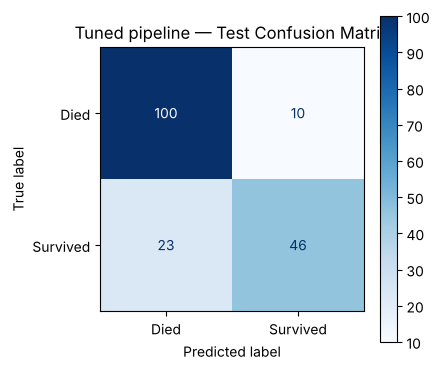

In [8]:
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, ConfusionMatrixDisplay

y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, y_proba):.3f}\n")
print(classification_report(y_test, y_pred, target_names=["Died", "Survived"]))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Died", "Survived"], cmap="Blues", ax=ax)
ax.set_title("Tuned pipeline — Test Confusion Matrix")
plt.tight_layout(); plt.savefig("images/confusion_matrix.png", dpi=120); plt.show()

## 10. Saving the Pipeline & Predicting for a New Passenger
The whole pipeline — preprocessing **and** model — is saved as one file. In deployment, raw passenger data
(with missing values, text categories, etc.) can be passed in directly.

In [9]:
import joblib

joblib.dump(best_pipeline, "titanic_pipeline.joblib")
loaded = joblib.load("titanic_pipeline.joblib")

new_passengers = pd.DataFrame([
    {"Pclass": 1, "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male", "Age": np.nan, "SibSp": 0, "Parch": 0, "Fare": 7.25, "Embarked": None},
])
new_passengers["survival_probability"] = loaded.predict_proba(new_passengers)[:, 1].round(3)
new_passengers

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,survival_probability
0,1,female,29.0,0,0,80.00,C,0.979
1,3,male,NaN,0,0,7.25,NaN,0.046


The second passenger has a **missing age and missing port** — the saved pipeline fills them automatically with the
training medians/modes, exactly as it did during training.

## 11. Why This Pipeline Design Is Effective
* **Prevents data leakage** — every preprocessing statistic is learned only from training data, including inside each CV fold.
* **Reproducible** — fixed random seeds and a single object containing every step.
* **Easy experimentation** — swapping or tuning the model is a one-line change (`model__max_depth`, etc.).
* **Deployment-ready** — one `.joblib` file turns raw input into a prediction; there is no separate preprocessing code to keep in sync.
* **Robust** — automatic column-type detection and `handle_unknown="ignore"` avoid crashes on new columns or unseen categories.

## 12. Conclusion
* In cross-validation, **Gradient Boosting (0.82 accuracy)** beat Random Forest and Logistic Regression (both ~0.79) with default settings.
* The combined grid search confirmed it: the best pipeline is **Gradient Boosting (200 trees, depth 4, learning rate 0.05)** with
  **0.83 cross-validation accuracy**, and it reached **0.82 accuracy on the untouched test set**. The CV and test scores are close,
  so the estimate is reliable and not over-fitted to the validation folds.
* **Trade-off:** recall for survivors is lower (0.67) than for non-survivors (0.91). Gradient Boosting has no `class_weight` option,
  so if missing a survivor were costly, the next step would be to lower the decision threshold or pass `sample_weight`.
* The final artefact is a single `titanic_pipeline.joblib` file that takes **raw** passenger data, including missing values,
  and returns a survival probability.

**Possible next steps:** add engineered features (passenger title, family size) as a custom transformer inside the pipeline,
tune the decision threshold, and serve the saved pipeline behind a small API (FastAPI/Flask).